Simulate a AT schedule from a trajectory.
- Take in params
- output Simulated AT

Simulate a complete trial. 

In [6]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
from scipy import stats
from pathlib import Path
import shutil
import cmdstanpy
import arviz as az

import matplotlib.pyplot as plt
from at_modelling.LotkaVolterraModel import LotkaVolterraModel
from utils.synth_data import draw_params, complete_param_dict, progress_on_ct, add_cycle_col, plot_n_rand_patients, prior_pred_checks


/Users/80002536/Documents/moffitt/at-modelling/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Lets call instantiate a lotka volterra model. We can call the paramDic to see what params it has set

In [7]:
np.random.seed(1)

#the model is set with default params
lv_model = LotkaVolterraModel()

print(f'Params:', lv_model.param_dic)
print(f'StateVars', lv_model.state_vars)

lv_model.set_params(rS=1)
lv_model.simulate_at(tumour_size_when_progressed=1.2)
lv_model.ode_df

Params: {'DMax': 1, 'rS': 0.027, 'rR': 0.027, 'K': 1, 'dD': 1.5, 'dS': 0.0, 'dR': 0.0, 'S0': 0.74, 'R0': 0.01, 'sigma': 0}
StateVars ['S', 'R']


,Time,DrugConcentration,S,R,TumourSize,Progressed
0,0.000,1.0,7.400000e-01,0.010000,0.750000,False
1,0.001,1.0,7.399075e-01,0.010000,0.749908,False
2,0.002,1.0,7.398150e-01,0.010000,0.749815,False
3,0.003,1.0,7.397224e-01,0.010000,0.749723,False
4,0.004,1.0,7.396298e-01,0.010000,0.749630,False
...,...,...,...,...,...,...
996,405.996,1.0,7.460966e-10,0.901840,0.901840,True
997,405.997,1.0,7.460600e-10,0.901842,0.901842,True
998,405.998,1.0,7.460234e-10,0.901845,0.901845,True
999,405.999,1.0,7.459867e-10,0.901847,0.901847,True


But it wont simulate yet. If you uncomment and run the following block, you should get an error that the model doesn't have an 'initialStateList'

In [8]:
#model_example.simulate_at()

We can set our own initial state list, or simply call the Setparams which will get the values from the param dic (R0, S0). Note that a number of arguments can be passed 

We see that We can the print the results. The default time resolution is very high. We can clean the df to longer intervals and also be sure to remove post progression obs

## part 2
We can use the model simulate an entire trial. We can the use this data to test out inferential pipeline such as a bayesian fitting routine. We can add some makeshift, but the proper way to do it would be flexible model code. 

Soft-prior copy of `genertate_synth_AT_trial_data.ipynb`. The prior on turnover is replaced by a prior on
`u = (1 - turnover / (1 - cost)) / n0`, the size the tumour levels off at on continuous therapy relative to its starting size.
`u > 1.2` means the patient progresses. turnover is computed back as `(1 - cost) * (1 - u * n0)`, and `u` has to be below `1 / n0`.
In the fit the prior on `u` is also truncated below at 1 (the generator only keeps `u > 1.2`, through the progression check).
The data go to `../synth_data_u` and the Stan model is `../stan/model_switchable_u.stan`.

P(u < 1.2): 0.03343241840891687


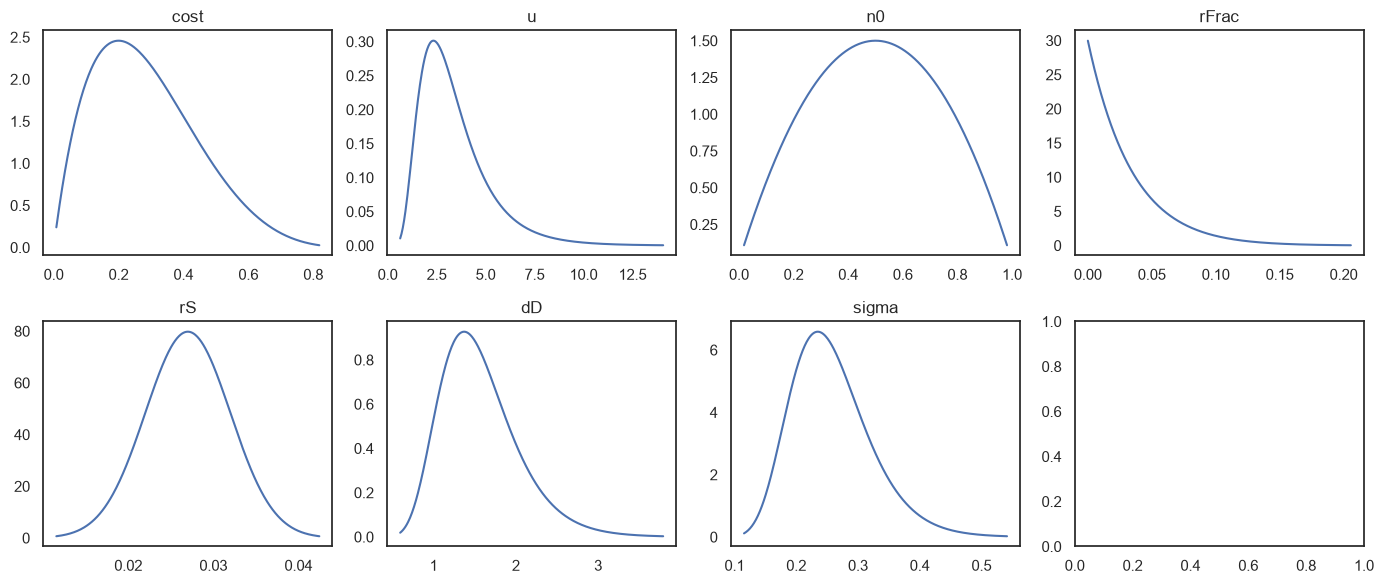

In [9]:
#priorDic is defined in fit_routine.py, so the recovery script and this notebook use the same priors
from fit_routine import priorDic

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (name, dist) in zip(axes.flat, priorDic.items()):
    x = np.linspace(*dist.ppf([0.001, 0.999]), 400)
    ax.plot(x, dist.pdf(x)); ax.set_title(name)

plt.tight_layout()

#amount of u below 1.2
print('P(u < 1.2):', priorDic["u"].cdf(1.2))

Generate synth patient data

Check passed or not checking progression on AT! Saving Patient 0 out of 205
Check passed or not checking progression on AT! Saving Patient 1 out of 205
Check passed or not checking progression on AT! Saving Patient 2 out of 205
Check passed or not checking progression on AT! Saving Patient 3 out of 205
Check passed or not checking progression on AT! Saving Patient 4 out of 205
Check passed or not checking progression on AT! Saving Patient 5 out of 205
Check passed or not checking progression on AT! Saving Patient 6 out of 205
Check passed or not checking progression on AT! Saving Patient 7 out of 205
Check passed or not checking progression on AT! Saving Patient 8 out of 205
Check passed or not checking progression on AT! Saving Patient 9 out of 205
Check passed or not checking progression on AT! Saving Patient 10 out of 205
Check passed or not checking progression on AT! Saving Patient 11 out of 205
Check passed or not checking progression on AT! Saving Patient 12 out of 205
Check pas

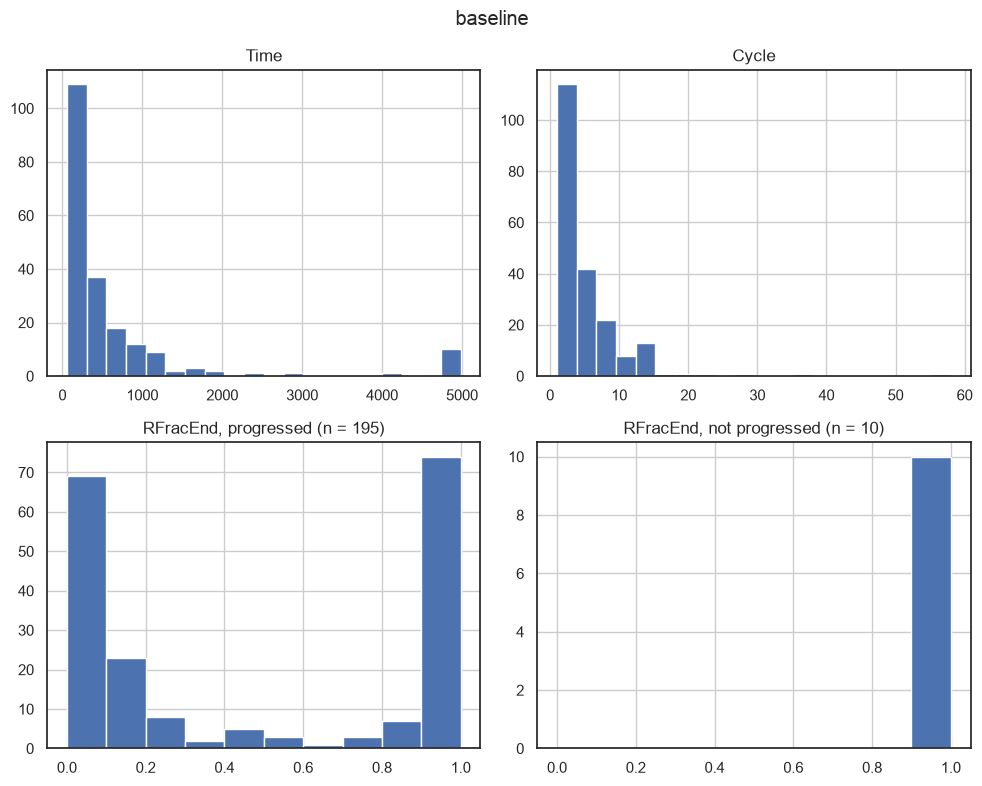

In [ ]:
# Generate random patients for each progression rule (deletes the folder first, fits included)
from utils.synth_data import generate_u_patients

n=250

np.random.seed(1)
synth_dir_baseline = Path('../prior_pred_baseline')
synth_df_baseline, true_params_baseline = generate_u_patients(priorDic, n_patients=n, out_dir=synth_dir_baseline, check_progression=False, progression='baseline')
synth_df_baseline = pd.read_csv(synth_dir_baseline / 'synth_patients.csv')

prior_pred_checks(synth_df_baseline, title='baseline');

Lets plot the patients we just generated.

Check passed or not checking progression on AT! Saving Patient 0 out of 205
Check passed or not checking progression on AT! Saving Patient 1 out of 205
Check passed or not checking progression on AT! Saving Patient 2 out of 205
Check passed or not checking progression on AT! Saving Patient 3 out of 205
Check passed or not checking progression on AT! Saving Patient 4 out of 205
Check passed or not checking progression on AT! Saving Patient 5 out of 205
Check passed or not checking progression on AT! Saving Patient 6 out of 205
Check passed or not checking progression on AT! Saving Patient 7 out of 205
Check passed or not checking progression on AT! Saving Patient 8 out of 205
Check passed or not checking progression on AT! Saving Patient 9 out of 205
Check passed or not checking progression on AT! Saving Patient 10 out of 205
Check passed or not checking progression on AT! Saving Patient 11 out of 205
Check passed or not checking progression on AT! Saving Patient 12 out of 205
Check pas

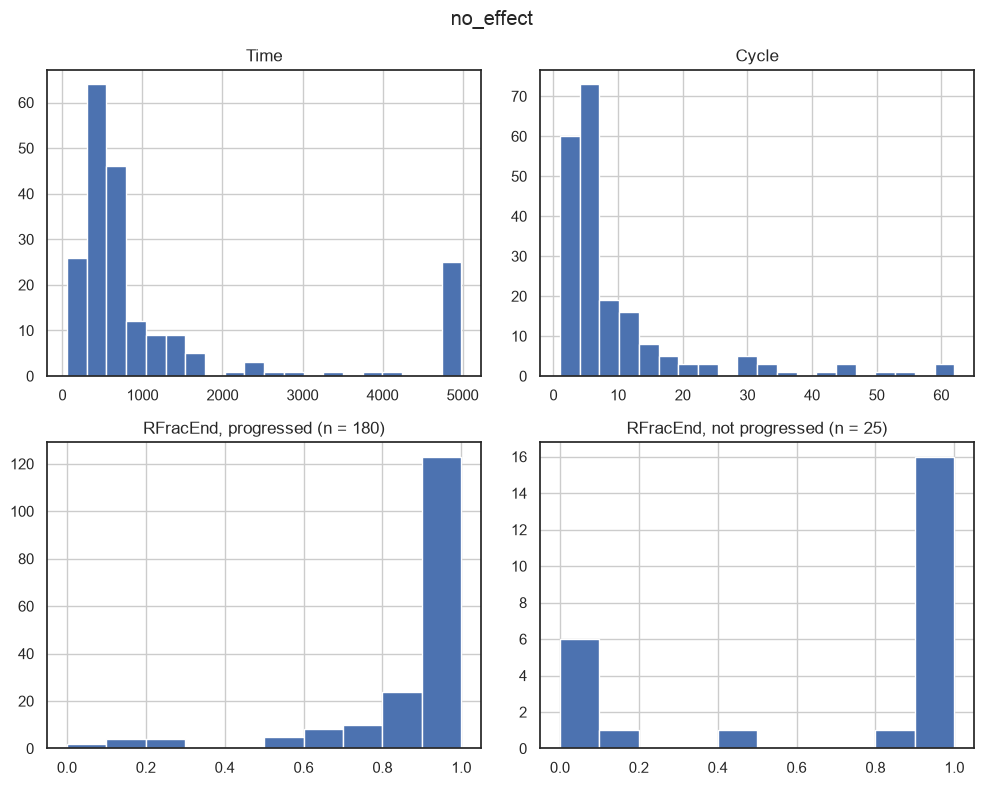

In [12]:
np.random.seed(1)  #same seed as baseline; the cohorts still drift apart once a run stops at a different check-up
synth_dir_no_effect = Path('../prior_pred_no_effect')
synth_df_no_effect, true_params_no_effect = generate_u_patients(priorDic, n_patients=n, out_dir=synth_dir_no_effect, check_progression=False, progression='no_effect')
synth_df_no_effect = pd.read_csv(synth_dir_no_effect / 'synth_patients.csv')

prior_pred_checks(synth_df_no_effect, title='no_effect');

see the rfracend is much higher than the expected u. We plot the emperically plotted dists. these might have changed due to rejection sampling the prior

In [ ]:
from synth_data import plo

And we can plot a set of the generated patient trajectories

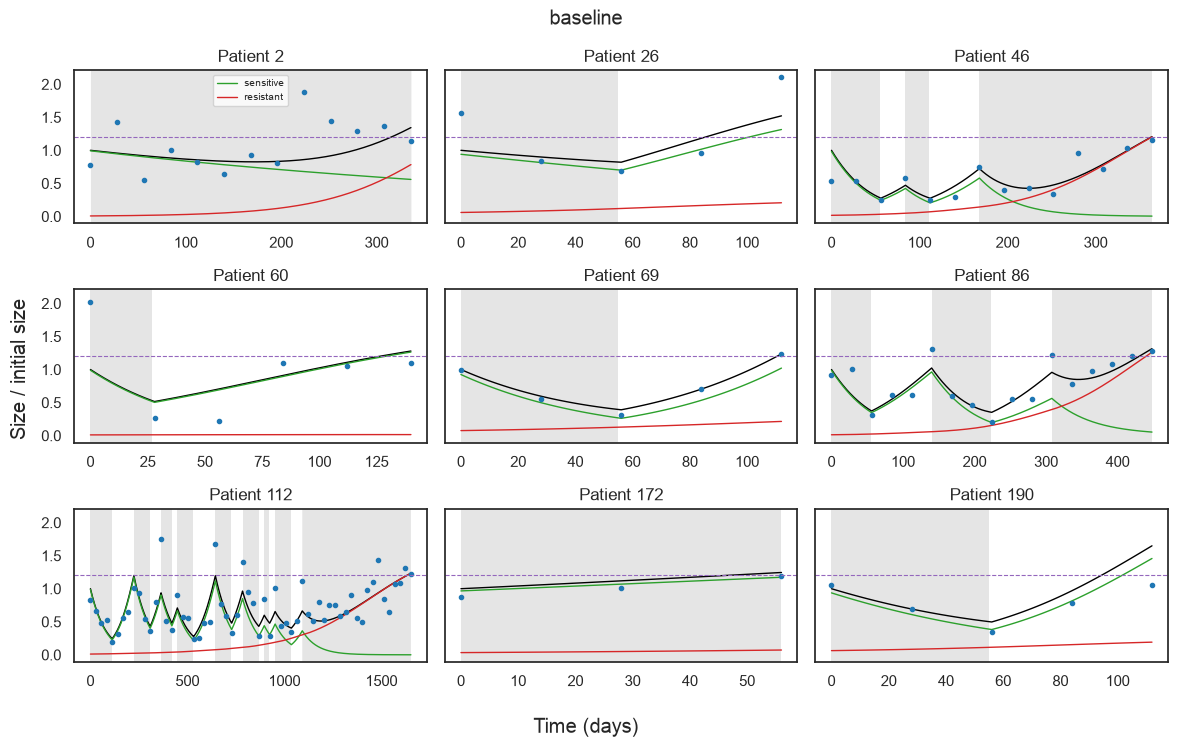

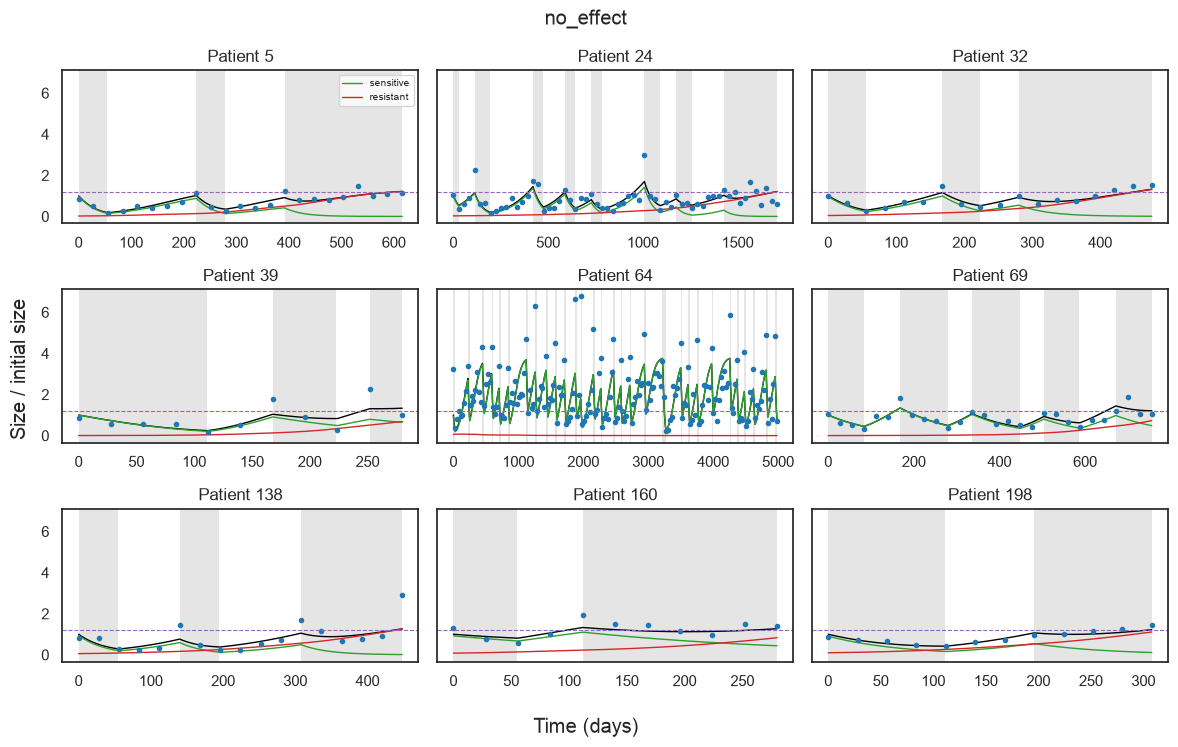

In [17]:
for rule, df in [('baseline', synth_df_baseline), ('no_effect', synth_df_no_effect)]:
    fig = plot_n_rand_patients(df, n=9, show_populations=True)
    fig.suptitle(rule); fig.tight_layout()  #redo the layout so the title does not cover the top panels


### part 3
Fitig one of these using stan. setup model data

In [ ]:
from utils.stan_data import to_stan_prior, make_stan_data, u_init

patient_id = 4

synth_dir = synth_dir_baseline  #the Stan cells below fit the baseline cohort
synth_df = pd.read_csv(synth_dir / 'synth_patients.csv')
stan_model = cmdstanpy.CmdStanModel(stan_file='../stan/model_switchable_u.stan')
priors = {f"{k}_prior": to_stan_prior(d) for k, d in priorDic.items()}
stan_data = make_stan_data(synth_df, patient_id=patient_id, priors=priors)

ValueError: No Stan conversion for norm

First we sample from priors only and compare priors put into the simulator

13:06:13 - cmdstanpy - INFO - CmdStan start processing
13:06:13 - cmdstanpy - INFO - Chain [1] start processing
13:06:13 - cmdstanpy - INFO - Chain [2] start processing
13:06:13 - cmdstanpy - INFO - Chain [3] start processing
13:06:13 - cmdstanpy - INFO - Chain [4] start processing
13:06:19 - cmdstanpy - INFO - Chain [1] done processing
13:06:20 - cmdstanpy - INFO - Chain [4] done processing
13:06:21 - cmdstanpy - INFO - Chain [3] done processing
13:06:21 - cmdstanpy - INFO - Chain [2] done processing
13:06:21 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: lub_constrain: lb is 1, but must be less than 1.000000 (in 'model_switchable_u.stan', line 65, column 2 to column 32)
	Exception: lub_constrain: lb is 1, but must be less than 1.000000 (in 'model_switchable_u.stan', line 65, column 2 to column 32)
Exception: lub_constrain: lb is 1, but must be less than 1.000000 (in 'model_switchable_u.stan', line 65, column 2 to column 32)
	Exception: lub_constrain: lb is 1, but

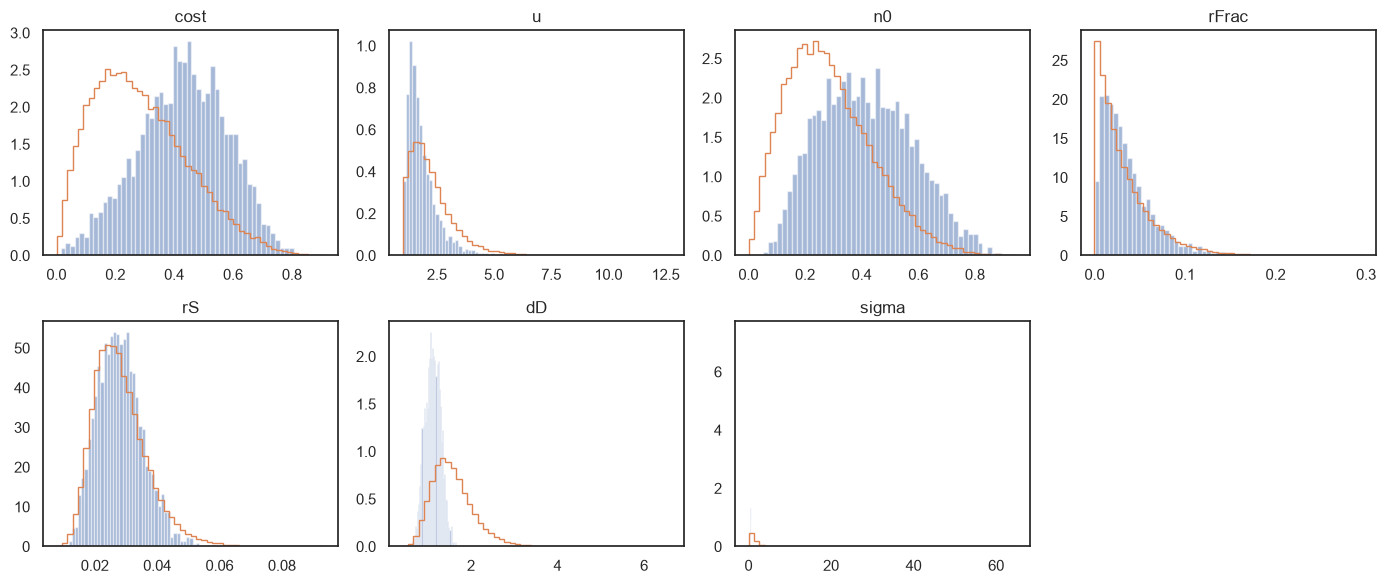

In [ ]:
#sample the prior with Stan and compare with priorDic
rng = np.random.default_rng(1)

#priorDic with the draws where u < 1 or u * n0 >= 1 removed, which is the prior Stan samples
ref = pd.DataFrame({k: d.rvs(100000, random_state=rng) for k, d in priorDic.items()})
ref = ref[(ref['u'] > 1) & (ref['u'] * ref['n0'] < 1)]

prior_fit = stan_model.sample(data=stan_data, chains=4, seed=1, inits=[u_init(priorDic, rng) for _ in range(4)], show_progress=False)
prior_draws = prior_fit.draws_pd(list(priorDic))

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (name, dist) in zip(axes.flat, priorDic.items()):
    ax.hist(prior_draws[name], bins=50, density=True, alpha=.5)
    ax.hist(ref[name], bins=50, density=True, histtype='step')
    ax.set_title(f"{name}")
axes.flat[-1].set_visible(False)
fig.tight_layout()

13:06:22 - cmdstanpy - INFO - Chain [1] start processing
13:06:22 - cmdstanpy - INFO - Chain [1] done processing
13:06:22 - cmdstanpy - INFO - CmdStan start processing
chain 1:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]



chain 1:   5%|▌         | 100/2000 [00:00<00:10, 184.93it/s, (Warmup)]



chain 1:  10%|█         | 200/2000 [00:00<00:07, 232.11it/s, (Warmup)]


chain 1:  15%|█▌        | 300/2000 [00:01<00:06, 273.75it/s, (Warmup)]


chain 1:  20%|██        | 400/2000 [00:01<00:05, 309.44it/s, (Warmup)]


chain 1:  25%|██▌       | 500/2000 [00:01<00:04, 311.61it/s, (Warmup)]


chain 1:  35%|███▌      | 700/2000 [00:02<00:03, 329.71it/s, (Warmup)]





chain 1:  45%|████▌     | 900/2000 [00:02<00:03, 362.70it/s, (Warmup)]







chain 1:  50%|█████     | 1000/2000 [00:03<00:02, 341.83it/s, (Sampling)]

chain 1:  55%|█████▌    | 1100/2000 [00:03<00:02, 330.54it/s, (Sampling)]






chain 1:  60%|██████    | 1200/2000 [00:03<00:02, 315.86it/s, (Sampling)]


chain 1:  65%|████


13:06:29 - cmdstanpy - INFO - CmdStan done processing.
13:06:29 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: lub_constrain: lb is 1, but must be less than 1.000000 (in 'model_switchable_u.stan', line 65, column 2 to column 32)
Exception: lub_constrain: lb is 1, but must be less than 1.000000 (in 'model_switchable_u.stan', line 65, column 2 to column 32)
Exception: ode_rk45: ode parameters and data[1] is inf, but must be finite! (in 'model_switchable_u.stan', line 115, column 4 to column 181)
	Exception: ode_rk45: initial state[1] is nan, but must be finite! (in 'model_switchable_u.stan', line 115, column 4 to column 181)
Exception: ode_rk45: ode parameters and data[3] is inf, but must be finite! (in 'model_switchable_u.stan', line 115, column 4 to column 181)
	Exception: ode_rk45: initial state[1] is nan, but must be finite! (in 'model_switchable_u.stan', line 115, column 4 to column 181)
	Exception: lub_constrain: lb is 1, but must be less than 1.000000 (in 'mo


divergences: 5
P(u > 1.2): 0.8955


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
cost,0.43,0.154,0.16,0.66,698,538,1.01,0.0059,0.0026
u,1.9,0.9,1.1,3.6,280,170,1.02,0.092,0.17
n0,0.42,0.18,0.13,0.71,282,175,1.02,0.0092,0.0061
rFrac,0.035,0.029,0.0047,0.093,2508,2169,1.00,0.00057,0.00087
rS,0.0283,0.0073,0.018,0.041,1340,2294,1.00,0.00019,0.00013
dD,1.126,0.186,0.83,1.4,1548,1812,1.01,0.0047,0.0034
sigma,0.395,0.059,0.31,0.5,1537,1492,1.00,0.0015,0.0013


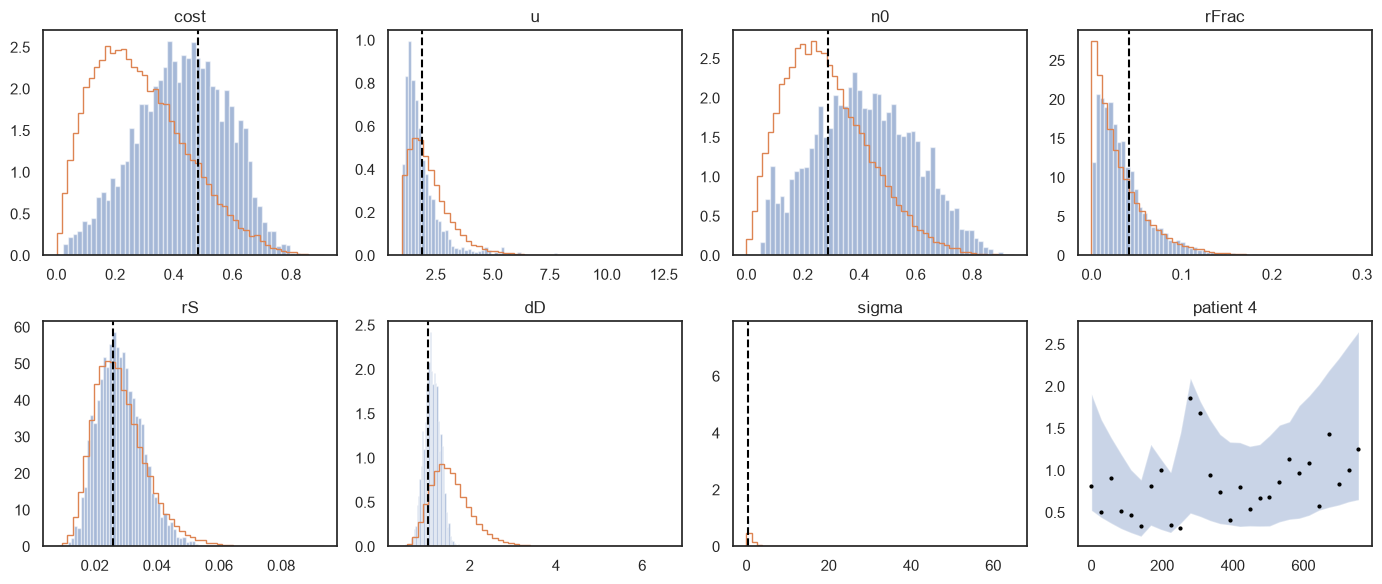

In [ ]:
truth = pd.read_csv(synth_dir / 'true_params.csv', index_col='PatientId').loc[patient_id]

#pathfinder inits: one approximate posterior draw per chain, started from a u_init() draw so u is below 1 / n0
pathfinder_fit = stan_model.pathfinder(data={**stan_data, 'prior_only': 0}, seed=1, inits=u_init(priorDic, rng))
pathfinder_inits = pathfinder_fit.create_inits(seed=1, chains=4)

#save_latent_dynamics: also write the unconstrained draws, used by the pair plot below
post_fit = stan_model.sample(data={**stan_data, 'prior_only': 0}, chains=4, seed=3, inits=pathfinder_inits,
                             adapt_delta=0.8, show_progress=True, save_latent_dynamics=True)
idata = az.from_cmdstanpy(posterior=post_fit)
print('divergences:', int(idata.sample_stats['diverging'].sum()))
print('P(u > 1.2):', float((idata.posterior['u'] > 1.2).mean()))
display(az.summary(idata, var_names=list(priorDic)))

post_draws = post_fit.draws_pd(list(priorDic))

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (name, dist) in zip(axes.flat, priorDic.items()):
    ax.hist(post_draws[name], bins=50, density=True, alpha=.5)
    ax.hist(ref[name], bins=50, density=True, histtype='step')
    ax.axvline(truth[name], color='black', ls='--')
    ax.set_title(name)
ax = axes.flat[-1]
ax.fill_between(stan_data['output_times'], *np.percentile(post_fit.stan_variable('PSA_pred'), [5, 95], axis=0), alpha=.3)
ax.plot(stan_data['output_times'], stan_data['PSA_norm'], 'o', ms=2, color='black')
ax.set_title(f'patient {patient_id}')
fig.tight_layout()

In [ ]:
#fit every patient with fit_patient from fit_routine.py: patient_<id>.nc and the chains' csvs (warmup and unconstrained
#draws too) go to synth_dir / 'fits', failed fits to errors.txt
from fit_routine import fit_all

#errors = fit_all(synth_df, synth_dir / 'fits', stan_model, priorDic, seed=1, overwrite=True)

13:06:30 - cmdstanpy - INFO - Chain [1] start processing
13:06:30 - cmdstanpy - INFO - Chain [1] done processing
13:06:30 - cmdstanpy - INFO - created output directory: /Users/80002536/Documents/moffitt/biomarker_uncertainty/synth_data_u/fits/patient_0_csv
13:06:30 - cmdstanpy - INFO - CmdStan start processing
chain 1:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]


chain 1:  10%|█         | 200/2000 [00:00<00:00, 1899.44it/s, (Warmup)]

chain 1:  35%|███▌      | 700/2000 [00:00<00:00, 3571.19it/s, (Warmup)]



chain 1:  65%|██████▌   | 1300/2000 [00:00<00:00, 4377.26it/s, (Sampling)]

chain 1:  95%|█████████▌| 1900/2000 [00:00<00:00, 4690.86it/s, (Sampling)]






chain 2: 100%|██████████| 2000/2000 [00:01<00:00, 1082.04it/s, (Sampling completed)]

chain 3: 100%|██████████| 2000/2000 [00:01<00:00, 1081.97it/s, (Sampling completed)]


chain 4: 100%|██████████| 2000/2000 [00:01<00:00, 1081.90it/s, (Sampling completed)]


13:06:32 - cmdstanpy - INFO - CmdStan done processing.
13:06:32 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: lub_constrain: lb is 1, but must be less than 1.000000 (in 'model_switchable_u.stan', line 65, column 2 to column 32)
	Exception: lub_constrain: lb is 1, but must be less than 1.000000 (in 'model_switchable_u.stan', line 65, column 2 to column 32)
Exception: ode_rk45:  Failed to integrate to next output time (28) in less than max_num_steps steps (in 'model_switchable_u.stan', line 115, column 4 to column 181)
Consider re-running with show_console=True if the above output is unclear!



Fitted patient 0 out of 250


13:06:32 - cmdstanpy - INFO - Chain [1] start processing
13:06:32 - cmdstanpy - INFO - Chain [1] done processing
13:06:32 - cmdstanpy - INFO - created output directory: /Users/80002536/Documents/moffitt/biomarker_uncertainty/synth_data_u/fits/patient_1_csv
13:06:32 - cmdstanpy - INFO - CmdStan start processing
chain 1:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]



chain 1:   5%|▌         | 100/2000 [00:00<00:03, 614.91it/s, (Warmup)]





























chain 2: 100%|██████████| 2000/2000 [00:05<00:00, 386.93it/s, (Sampling completed)] 

chain 3: 100%|██████████| 2000/2000 [00:05<00:00, 386.91it/s, (Sampling completed)] 


chain 4: 100%|██████████| 2000/2000 [00:05<00:00, 386.90it/s, (Sampling completed)] 


13:06:37 - cmdstanpy - INFO - CmdStan done processing.
13:06:37 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: ode_rk45:  Failed to integrate to next output time (28) in less than max_num_steps steps (in 'model_switchable_u.stan', line 115, column 4 to column 181)
Exception: lub_constrain: lb is 1, but must be less than 1.000000 (in 'model_switchable_u.stan', line 65, column 2 to column 32)
Exception: lub_constrain: lb is 1, but must be less than 1.000000 (in 'model_switchable_u.stan', line 65, column 2 to column 32)
Consider re-running with show_console=True if the above output is unclear!
13:06:38 - cmdstanpy - INFO - Chain [1] start processing



Fitted patient 1 out of 250


... (18 outputs left out)


Fitted patient 7 out of 250


13:07:14 - cmdstanpy - INFO - Chain [1] done processing
13:07:14 - cmdstanpy - INFO - created output directory: /Users/80002536/Documents/moffitt/biomarker_uncertainty/synth_data_u/fits/patient_8_csv
13:07:14 - cmdstanpy - INFO - CmdStan start processing
chain 1:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]




chain 1:   5%|▌         | 100/2000 [00:00<00:08, 225.60it/s, (Warmup)]



chain 1:  10%|█         | 200/2000 [00:00<00:04, 369.79it/s, (Warmup)]

chain 1:  15%|█▌        | 300/2000 [00:00<00:03, 501.77it/s, (Warmup)]


chain 1:  20%|██        | 400/2000 [00:00<00:02, 612.15it/s, (Warmup)]


chain 1:  25%|██▌       | 500/2000 [00:00<00:02, 711.18it/s, (Warmup)]


chain 1:  35%|███▌      | 700/2000 [00:01<00:01, 835.49it/s, (Warmup)]


chain 1:  40%|████      | 800/2000 [00:01<00:01, 872.39it/s, (Warmup)]




chain 1:  50%|█████     | 1000/2000 [00:01<00:01, 929.65it/s, (Sampling)]

chain 1:  55%|█████▌    | 1100/2000 [00:01<00:00, 929.48it/s, (Sampling)]

chain 1:  60%|████

KeyboardInterrupt: 



chain 1:  90%|█████████ | 1800/2000 [00:13<00:00, 866.54it/s, (Sampling)]


In [ ]:
import arviz_stats as azs

#loop over files in fit folder
for path in sorted((synth_dir / 'fits').glob('*.nc')):
    # read in fit
    idata = az.from_netcdf(path)
    # call arviz diagnose on fit
    problematic, diagnostics = azs.diagnose(idata, var_names=list(priorDic), show_diagnostics=False, return_diagnostics=True)
    if problematic: 
        print(f'{path.name}: {diagnostics}\n')

patient_4.nc: {'divergent': {'n_divergent': 1, 'pct': np.float64(0.025), 'total_samples': np.int64(4000)}, 'bfmi': {'bfmi_values': array([0.95378195, 0.87911916, 0.98173192, 0.89083995]), 'failed_chains': [], 'threshold': 0.3}, 'ess': {'bad_params': [], 'ess_values': <xarray.Dataset> Size: 0B
Dimensions:  ()
Data variables:
    *empty*, 'threshold_ratio': 0.001, 'total_samples': np.int64(4000)}, 'rhat': {'bad_params': [], 'rhat_values': <xarray.Dataset> Size: 0B
Dimensions:  ()
Data variables:
    *empty*, 'threshold': 1.01}}

